In [1]:
import time
import numpy as np
import pandas as pd
import scipy.sparse as sp

neurons = pd.read_parquet("../data/neurons.parquet")
W = sp.load_npz("../data/W.npz")
print(neurons.shape, W.shape)
print("Row labels match positions:", (neurons.index == np.arange(len(neurons))).all())

(166700, 9) (166700, 166700)
Row labels match positions: True


In [2]:
def find_types(text):
    mask = neurons["type"].str.contains(text, case=False, na=False)
    return neurons[mask].groupby(["type", "superclass"]).size()

find_types("DA1")

type     superclass  
DA1_lPN  cb_intrinsic     13
DA1_vPN  cb_intrinsic      2
ORN_DA1  cb_sensory      204
dtype: int64

In [3]:
dt = 0.1
v_rest, v_reset, v_th = -52.0, -52.0, -45.0
tau_m, tau_syn = 20.0, 5.0
t_ref, delay = 2.2, 1.8
w_syn = 0.275
stim_rate = 150.0
stim_strength = 250 * w_syn

In [4]:
def simulate_brain(W, stim, duration_ms=1000, seed=0):
    n = W.shape[0]
    steps = int(duration_ms / dt)
    delay_steps = int(delay / dt)
    ref_steps = int(t_ref / dt)
    rng = np.random.default_rng(seed)

    W_mv = (W * w_syn).astype(np.float32).tocsr()
    v = np.full(n, v_rest, dtype=np.float32)
    g = np.zeros(n, dtype=np.float32)
    ref = np.zeros(n, dtype=np.int32)
    buffer = np.zeros((delay_steps, n), dtype=np.float32)
    spike_counts = np.zeros(n, dtype=np.int32)

    start = time.time()
    for t in range(steps):
        slot = t % delay_steps
        g += buffer[slot]
        buffer[slot] = 0

        hits = stim[rng.random(len(stim)) < stim_rate * dt / 1000]
        g[hits] += stim_strength

        v += dt * (v_rest - v + g) / tau_m
        g -= dt * g / tau_syn

        refractory = ref > 0
        v[refractory] = v_reset
        ref[refractory] -= 1

        fired = np.flatnonzero((v >= v_th) & ~refractory)
        v[fired] = v_reset
        ref[fired] = ref_steps
        spike_counts[fired] += 1

        if len(fired) > 0:
            buffer[slot] += np.asarray(W_mv[fired].sum(axis=0)).ravel()

        if t % 1000 == 0:
            print(f"{t * dt:6.0f} ms simulated, {time.time() - start:5.1f} s elapsed, "
                  f"{len(fired)} neurons firing now", flush=True)

    return spike_counts / (duration_ms / 1000)

In [5]:
stim = np.flatnonzero(neurons["type"] == "ORN_DA1")
print(f"Stimulating {len(stim)} neurons")

rates = simulate_brain(W, stim, duration_ms=1000)

Stimulating 204 neurons
     0 ms simulated,   0.0 s elapsed, 0 neurons firing now
   100 ms simulated,   1.1 s elapsed, 370 neurons firing now
   200 ms simulated,   2.3 s elapsed, 332 neurons firing now
   300 ms simulated,   3.5 s elapsed, 358 neurons firing now
   400 ms simulated,   4.6 s elapsed, 319 neurons firing now
   500 ms simulated,   5.8 s elapsed, 371 neurons firing now
   600 ms simulated,   7.1 s elapsed, 318 neurons firing now
   700 ms simulated,   8.4 s elapsed, 356 neurons firing now
   800 ms simulated,   9.5 s elapsed, 314 neurons firing now
   900 ms simulated,  10.7 s elapsed, 316 neurons firing now


In [6]:
results = neurons[["bodyId", "type", "superclass", "consensus_nt"]].copy()
results["rate_hz"] = rates

responders = results[(results["rate_hz"] > 0) & ~results.index.isin(stim)]
print(f"{len(responders)} neurons fired (not counting the stimulated ones)")

(responders.groupby(["type", "superclass"])["rate_hz"]
           .agg(["count", "mean"])
           .sort_values("mean", ascending=False)
           .head(25))

25727 neurons fired (not counting the stimulated ones)


,,count,mean
type,superclass,,
il3LN6,cb_intrinsic,2,432.500000
v2LN30,cb_intrinsic,2,432.000000
lLN2F_b,cb_intrinsic,4,431.250000
lLN2X04,cb_intrinsic,4,431.000000
lLN2P_a,cb_intrinsic,7,430.571429
lLN2T_e,cb_intrinsic,4,430.500000
lLN2P_b,cb_intrinsic,12,430.250000
lLN1_a,cb_intrinsic,2,430.000000
DC1_adPN,cb_intrinsic,2,430.000000


In [7]:
firing = results[results["rate_hz"] > 0]
print(f"Neurons firing: {len(firing):,} of {len(results):,}")
print(f"Neurons near the ceiling (>400 Hz): {(results['rate_hz'] > 400).sum():,}")

print("\nDA1 projection neurons:")
print(results[results["type"].str.startswith("DA1_", na=False)][["type", "rate_hz"]])

print("\nFiring neurons by superclass:")
firing.groupby("superclass").size().sort_values(ascending=False)

Neurons firing: 25,931 of 166,700
Neurons near the ceiling (>400 Hz): 310

DA1 projection neurons:
         type  rate_hz
62    DA1_lPN    405.0
1458  DA1_lPN    378.0
1607  DA1_lPN    393.0
1661  DA1_lPN    414.0
1694  DA1_lPN    414.0
1866  DA1_lPN    414.0
1983  DA1_lPN    414.0
2162  DA1_lPN    397.0
2186  DA1_lPN    414.0
2435  DA1_vPN    381.0
2481  DA1_lPN    382.0
2867  DA1_lPN    414.0
3000  DA1_vPN    414.0
3256  DA1_lPN    396.0
3346  DA1_lPN    369.0

Firing neurons by superclass:


superclass
cb_intrinsic           15772
vnc_intrinsic           3578
ol_intrinsic            2974
cb_sensory              1246
descending_neuron        563
visual_projection        537
ascending_neuron         505
vnc_motor                320
visual_centrifugal       235
cb_motor                  60
sensory_ascending         51
vnc_efferent              45
vnc_endocrine             18
cb_endocrine              15
efferent_ascending         6
efferent_descending        3
vnc_sensory                2
vnc_tbc                    1
dtype: int64

In [9]:
def simulate_brain(W, stim, duration_ms=1000, seed=0, weight_scale=1.0):   # changed
    n = W.shape[0]
    steps = int(duration_ms / dt)
    delay_steps = int(delay / dt)
    ref_steps = int(t_ref / dt)
    rng = np.random.default_rng(seed)

    W_mv = (W * (w_syn * weight_scale)).astype(np.float32).tocsr()          # changed
    v = np.full(n, v_rest, dtype=np.float32)
    g = np.zeros(n, dtype=np.float32)
    ref = np.zeros(n, dtype=np.int32)
    buffer = np.zeros((delay_steps, n), dtype=np.float32)
    spike_counts = np.zeros(n, dtype=np.int32)

    start = time.time()
    for t in range(steps):
        slot = t % delay_steps
        g += buffer[slot]
        buffer[slot] = 0

        hits = stim[rng.random(len(stim)) < stim_rate * dt / 1000]
        g[hits] += stim_strength

        v += dt * (v_rest - v + g) / tau_m
        g -= dt * g / tau_syn

        refractory = ref > 0
        v[refractory] = v_reset
        ref[refractory] -= 1

        fired = np.flatnonzero((v >= v_th) & ~refractory)
        v[fired] = v_reset
        ref[fired] = ref_steps
        spike_counts[fired] += 1

        if len(fired) > 0:
            buffer[slot] += np.asarray(W_mv[fired].sum(axis=0)).ravel()

        if t % 1000 == 0:
            print(f"{t * dt:6.0f} ms simulated, {time.time() - start:5.1f} s elapsed, "
                  f"{len(fired)} neurons firing now", flush=True)

    return spike_counts / (duration_ms / 1000)

In [10]:
rates = simulate_brain(W, stim, duration_ms=300, weight_scale=0.581)

results["rate_hz"] = rates
firing = results[results["rate_hz"] > 0]
print(f"Neurons firing: {len(firing):,}")
print(f"Near the ceiling: {(results['rate_hz'] > 400).sum():,}")
print(results[results["type"].str.startswith("DA1_", na=False)][["type", "rate_hz"]])

     0 ms simulated,   0.0 s elapsed, 0 neurons firing now
   100 ms simulated,   1.1 s elapsed, 183 neurons firing now
   200 ms simulated,   2.1 s elapsed, 199 neurons firing now
Neurons firing: 16,774
Near the ceiling: 81
         type     rate_hz
62    DA1_lPN  370.000000
1458  DA1_lPN  323.333333
1607  DA1_lPN  346.666667
1661  DA1_lPN  390.000000
1694  DA1_lPN  376.666667
1866  DA1_lPN  390.000000
1983  DA1_lPN  390.000000
2162  DA1_lPN  353.333333
2186  DA1_lPN  383.333333
2435  DA1_vPN  330.000000
2481  DA1_lPN  333.333333
2867  DA1_lPN  390.000000
3000  DA1_vPN  373.333333
3256  DA1_lPN  346.666667
3346  DA1_lPN  313.333333


In [11]:
bins = [0, 1, 10, 50, 100, 200, 500]
labels = ["0", "1–10", "10–50", "50–100", "100–200", "200+"]
results["rate_band"] = pd.cut(results["rate_hz"], bins=bins, labels=labels, right=False)
results["rate_band"].value_counts().sort_index()

rate_band
0          149926
1–10         2500
10–50        4351
50–100       2437
100–200      4190
200+         3296
Name: count, dtype: int64

In [12]:
strong = results[(results["rate_hz"] >= 50) & ~results.index.isin(stim)]
print(f"{len(strong)} neurons firing at 50 Hz or more")

(strong.groupby(["type", "superclass", "consensus_nt"])["rate_hz"]
       .agg(["count", "mean"])
       .sort_values("mean", ascending=False)
       .head(30))

9719 neurons firing at 50 Hz or more


,,,count,mean
type,superclass,consensus_nt,,
il3LN6,cb_intrinsic,gaba,2,423.333333
v2LN30,cb_intrinsic,unclear,2,421.666667
lLN2F_b,cb_intrinsic,gaba,4,419.166667
lLN2X04,cb_intrinsic,acetylcholine,4,416.666667
lLN2T_e,cb_intrinsic,acetylcholine,4,415.000000
lLN1_a,cb_intrinsic,acetylcholine,2,413.333333
lLN1_bc,cb_intrinsic,acetylcholine,30,412.888889
lLN2T_a,cb_intrinsic,acetylcholine,5,410.666667
lLN2P_a,cb_intrinsic,gaba,7,410.476190


## A dose-response experiment

In [13]:
is_pn = (results["type"].str.contains("PN", na=False) &
         (results["superclass"] == "cb_intrinsic")).to_numpy()
is_da1 = results["type"].str.startswith("DA1_", na=False).to_numpy()
is_other_pn = is_pn & ~is_da1

print("DA1 PNs:", is_da1.sum(), " Other PNs:", is_other_pn.sum())

DA1 PNs: 15  Other PNs: 793


In [14]:
all_orns = np.flatnonzero(neurons["type"] == "ORN_DA1")
pick = np.random.default_rng(42)

rows = []
for k in [5, 10, 25, 50, 100, 204]:
    stim_k = pick.choice(all_orns, size=k, replace=False)
    r = simulate_brain(W, stim_k, duration_ms=300, weight_scale=0.581)
    rows.append({
        "ORNs stimulated": k,
        "DA1 PN rate": r[is_da1].mean(),
        "other PN rate": r[is_other_pn].mean(),
        "neurons ≥50 Hz": int((r >= 50).sum()) - k,
    })

dose = pd.DataFrame(rows)
dose

     0 ms simulated,   0.0 s elapsed, 0 neurons firing now
   100 ms simulated,   0.6 s elapsed, 172 neurons firing now
   200 ms simulated,   1.7 s elapsed, 213 neurons firing now
     0 ms simulated,   0.0 s elapsed, 0 neurons firing now
   100 ms simulated,   0.7 s elapsed, 204 neurons firing now
   200 ms simulated,   1.6 s elapsed, 175 neurons firing now
     0 ms simulated,   0.0 s elapsed, 0 neurons firing now
   100 ms simulated,   0.8 s elapsed, 204 neurons firing now
   200 ms simulated,   1.8 s elapsed, 205 neurons firing now
     0 ms simulated,   0.0 s elapsed, 0 neurons firing now
   100 ms simulated,   0.8 s elapsed, 199 neurons firing now
   200 ms simulated,   1.8 s elapsed, 207 neurons firing now
     0 ms simulated,   0.0 s elapsed, 0 neurons firing now
   100 ms simulated,   0.8 s elapsed, 204 neurons firing now
   200 ms simulated,   1.8 s elapsed, 204 neurons firing now
     0 ms simulated,   0.0 s elapsed, 0 neurons firing now
   100 ms simulated,   0.9 s elapsed

,ORNs stimulated,DA1 PN rate,other PN rate,neurons ≥50 Hz
0,5,72.444444,131.820092,8867
1,10,98.222222,148.259773,9352
2,25,170.000000,154.266499,9570
3,50,247.555556,156.809584,9659
4,100,316.666667,159.289617,9718
5,204,360.888889,160.004203,9697


## Two diagnostic tests

In [15]:
self_w = W.diagonal()
print("Neurons with self-connections:", (self_w != 0).sum())
print("  excitatory:", (self_w > 0).sum(), "  inhibitory:", (self_w < 0).sum())

(neurons.assign(self_synapses=self_w)
        .sort_values("self_synapses", ascending=False)
        [["type", "superclass", "consensus_nt", "self_synapses"]]
        .head(15))

Neurons with self-connections: 101
  excitatory: 74   inhibitory: 27


,type,superclass,consensus_nt,self_synapses
165556,MN11V,cb_motor,acetylcholine,29
165005,MN1,cb_motor,acetylcholine,20
142588,MN3L,cb_motor,acetylcholine,17
165436,claw_tpGRN,cb_sensory,acetylcholine,17
166036,LB2a,cb_sensory,acetylcholine,14
165529,claw_tpGRN,cb_sensory,acetylcholine,12
144014,MN1,cb_motor,acetylcholine,11
165499,claw_tpGRN,cb_sensory,acetylcholine,11
64542,MN3L,cb_motor,acetylcholine,10
164127,LB4b,cb_sensory,acetylcholine,10


## Updated simulator (replace your existing simulator cell entirely)

In [25]:
stim_kick = 250 * w_syn

def simulate_brain(W, stim, duration_ms=1000, seed=0, weight_scale=1.0, stim_rate=stim_rate,
                   stim_off_ms=None, remove_self_connections=False, verbose=True):
    n = W.shape[0]
    steps = int(duration_ms / dt)
    delay_steps = int(delay / dt)
    ref_steps = int(t_ref / dt)
    rng = np.random.default_rng(seed)

    W_mv = (W * (w_syn * weight_scale)).astype(np.float32).tocsr()
    if remove_self_connections:
        W_mv = (W_mv - sp.diags(W_mv.diagonal())).tocsr()
        W_mv.eliminate_zeros()

    v = np.full(n, v_rest, dtype=np.float32)
    g = np.zeros(n, dtype=np.float32)
    ref = np.zeros(n, dtype=np.int32)
    buffer = np.zeros((delay_steps, n), dtype=np.float32)
    spike_counts = np.zeros(n, dtype=np.int32)
    activity = np.zeros(steps, dtype=np.int32)

    gets_refractory = np.ones(n, dtype=bool)
    gets_refractory[stim] = False

    start = time.time()
    for t in range(steps):
        slot = t % delay_steps
        g += buffer[slot]
        buffer[slot] = 0

        if stim_off_ms is None or t * dt < stim_off_ms:
            hits = stim[rng.random(len(stim)) < stim_rate * dt / 1000]
            v[hits] += stim_kick

        awake = ref == 0
        v[awake] += dt * (v_rest - v[awake] + g[awake]) / tau_m
        g[awake] -= dt * g[awake] / tau_syn
        ref[~awake] -= 1

        fired = np.flatnonzero((v > v_th) & awake)
        v[fired] = v_reset
        g[fired] = 0
        ref[fired[gets_refractory[fired]]] = ref_steps

        spike_counts[fired] += 1
        activity[t] = len(fired)

        if len(fired) > 0:
            buffer[slot] += np.asarray(W_mv[fired].sum(axis=0)).ravel()

        if verbose and t % 1000 == 0:
            print(f"{t * dt:6.0f} ms simulated, {time.time() - start:5.1f} s elapsed, "
                  f"{len(fired)} neurons firing now", flush=True)

    rates = spike_counts / (duration_ms / 1000)
    return rates, activity

## The switch-off test, with and without self-connections

original: 9,207 neurons ≥50 Hz, spikes in last 100 ms: 198,656
self-connections removed: 9,210 neurons ≥50 Hz, spikes in last 100 ms: 198,413


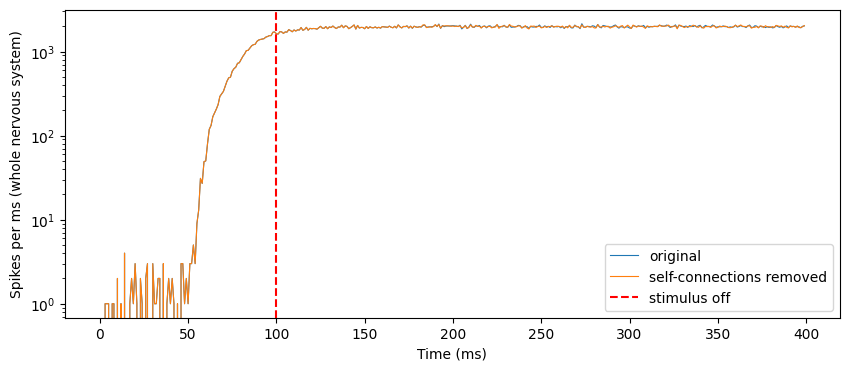

In [17]:
import matplotlib.pyplot as plt

stim_5 = np.random.default_rng(42).choice(all_orns, size=5, replace=False)

runs = {
    "original": dict(),
    "self-connections removed": dict(remove_self_connections=True),
}

plt.figure(figsize=(10, 4))
for label, options in runs.items():
    rates, activity = simulate_brain(W, stim_5, duration_ms=400, weight_scale=0.581,
                                     stim_off_ms=100, verbose=False, **options)
    spikes_per_ms = activity.reshape(-1, 10).sum(axis=1)
    plt.plot(spikes_per_ms, label=label, linewidth=0.8)
    print(f"{label}: {(rates >= 50).sum():,} neurons ≥50 Hz, "
          f"spikes in last 100 ms: {spikes_per_ms[300:].sum():,}")

plt.axvline(100, color="red", linestyle="--", label="stimulus off")
plt.xlabel("Time (ms)")
plt.ylabel("Spikes per ms (whole nervous system)")
plt.yscale("log")
plt.legend()
plt.show()

## Find the loop, and find the tipping point

In [18]:
results["rate_hz"] = rates
core = results[results["rate_hz"] >= 50]
print(f"{len(core):,} neurons in the self-sustaining state\n")

print(core.groupby("superclass").size().sort_values(ascending=False).head(10))
print()
print(core.groupby("consensus_nt").size().sort_values(ascending=False))

9,210 neurons in the self-sustaining state

superclass
cb_intrinsic          8274
vnc_intrinsic          246
cb_sensory             159
descending_neuron      110
ascending_neuron        98
ol_intrinsic            91
vnc_motor               79
visual_centrifugal      77
visual_projection       40
vnc_efferent            13
dtype: int64

consensus_nt
acetylcholine    6013
gaba             1461
glutamate         963
dopamine          362
unclear           349
octopamine         51
serotonin          11
dtype: int64


In [19]:
rows = []
for scale in [0.581, 0.5, 0.4, 0.3, 0.2]:
    r, act = simulate_brain(W, stim_5, duration_ms=400, weight_scale=scale,
                            stim_off_ms=100, verbose=False)
    per_ms = act.reshape(-1, 10).sum(axis=1)
    rows.append({
        "weight_scale": scale,
        "peak spikes/ms": int(per_ms.max()),
        "spikes after stimulus (last 100 ms)": int(per_ms[300:].sum()),
        "DA1 PN rate": r[is_da1].mean(),
    })
    print(f"scale {scale} done", flush=True)

pd.DataFrame(rows)

scale 0.581 done
scale 0.5 done
scale 0.4 done
scale 0.3 done
scale 0.2 done


,weight_scale,peak spikes/ms,spikes after stimulus (last 100 ms),DA1 PN rate
0,0.581,2145,198656,69.000000
1,0.500,1783,165469,62.000000
2,0.400,4,0,0.500000
3,0.300,4,0,0.166667
4,0.200,4,0,0.000000


## Test the dopamine hypothesis

In [20]:
is_kc = results["type"].str.startswith("KC", na=False)
print(f"Kenyon cells: {(is_kc & (results['rate_hz'] >= 50)).sum():,} "
      f"in core, of {is_kc.sum():,} total\n")

for transmitter in ["dopamine", "octopamine", "serotonin"]:
    total = (neurons["consensus_nt"] == transmitter).sum()
    in_core = (core["consensus_nt"] == transmitter).sum()
    print(f"{transmitter:12} {in_core:4} of {total:4} in core")

print("\nMost common types in the core:")
core["type"].value_counts().head(15)

Kenyon cells: 4,064 in core, of 4,064 total

dopamine      362 of  392 in core
octopamine     51 of  101 in core
serotonin      11 of   48 in core

Most common types in the core:


type
KCg-m         1342
KCab-s         657
KCab-m         536
KCab-c         488
KCa'b'-ap2     291
KCg-d          206
KCa'b'-m       205
KCa'b'-ap1     199
KCab-p         129
PAM08           50
PAM01           44
PAM04           32
lLN1_bc         30
PAM06           28
EPG             27
Name: count, dtype: int64

In [21]:
modulators = ["dopamine", "octopamine", "serotonin"]
is_modulator = neurons["consensus_nt"].isin(modulators).to_numpy()
print("Modulatory neurons:", is_modulator.sum())

row_keep = sp.diags((~is_modulator).astype(np.float32))
W_nomod = (row_keep @ W).tocsr()
print("Connections before:", W.nnz, " after:", W_nomod.count_nonzero())

Modulatory neurons: 541
Connections before: 25582938  after: 25147397


In [22]:
r, act = simulate_brain(W_nomod, stim_5, duration_ms=400, weight_scale=0.581,
                        stim_off_ms=100, verbose=False)
per_ms = act.reshape(-1, 10).sum(axis=1)
print(f"Peak spikes/ms: {per_ms.max():,}")
print(f"Spikes after stimulus (last 100 ms): {per_ms[300:].sum():,}")

rows = []
for k in [5, 25, 100, 204]:
    stim_k = np.random.default_rng(42).choice(all_orns, size=k, replace=False)
    r, _ = simulate_brain(W_nomod, stim_k, duration_ms=300, weight_scale=0.581, verbose=False)
    rows.append({
        "ORNs stimulated": k,
        "DA1 PN rate": r[is_da1].mean(),
        "other PN rate": r[is_other_pn].mean(),
        "neurons ≥50 Hz": int((r >= 50).sum()) - k,
    })
pd.DataFrame(rows)

Peak spikes/ms: 1,462
Spikes after stimulus (last 100 ms): 135,438


,ORNs stimulated,DA1 PN rate,other PN rate,neurons ≥50 Hz
0,5,65.111111,126.662463,6738
1,25,157.333333,147.751156,7235
2,100,314.666667,153.413199,7452
3,204,359.777778,154.459857,7504


In [23]:
is_kc_np = is_kc.to_numpy()
W_abs = abs(W)

kc_out = W_abs[is_kc_np]
kc_to_kc = kc_out[:, is_kc_np].sum()
kc_to_all = kc_out.sum()
print(f"Kenyon cell output synapses: {kc_to_all:,.0f}")
print(f"  onto other Kenyon cells:   {kc_to_kc:,.0f}  ({100 * kc_to_kc / kc_to_all:.0f}%)")

Kenyon cell output synapses: 2,246,626
  onto other Kenyon cells:   1,153,845  (51%)


In [24]:
coo = W_nomod.tocoo()
kc_pair = is_kc_np[coo.row] & is_kc_np[coo.col]
W_fixed = sp.csr_matrix((coo.data[~kc_pair], (coo.row[~kc_pair], coo.col[~kc_pair])),
                        shape=W.shape)
print("Removed KC→KC connections:", kc_pair.sum())

r, act = simulate_brain(W_fixed, stim_5, duration_ms=400, weight_scale=0.581,
                        stim_off_ms=100, verbose=False)
per_ms = act.reshape(-1, 10).sum(axis=1)
print(f"Peak spikes/ms: {per_ms.max():,}")
print(f"Spikes after stimulus (last 100 ms): {per_ms[300:].sum():,}")

rows = []
for k in [5, 25, 100, 204]:
    stim_k = np.random.default_rng(42).choice(all_orns, size=k, replace=False)
    r, _ = simulate_brain(W_fixed, stim_k, duration_ms=300, weight_scale=0.581, verbose=False)
    rows.append({
        "ORNs stimulated": k,
        "DA1 PN rate": r[is_da1].mean(),
        "other PN rate": r[is_other_pn].mean(),
        "neurons ≥50 Hz": int((r >= 50).sum()) - k,
    })
pd.DataFrame(rows)

Removed KC→KC connections: 642933
Peak spikes/ms: 982
Spikes after stimulus (last 100 ms): 87,427


,ORNs stimulated,DA1 PN rate,other PN rate,neurons ≥50 Hz
0,5,63.555556,125.657839,4442
1,25,155.111111,146.742329,5137
2,100,313.111111,152.366541,5346
3,204,359.777778,153.455233,5414


In [26]:
tests = {
    "original W": W,
    "W_fixed (no modulators, no KC→KC)": W_fixed,
}

for label, matrix in tests.items():
    r, act = simulate_brain(matrix, stim_5, duration_ms=400, weight_scale=0.581,
                            stim_off_ms=100, verbose=False)
    per_ms = act.reshape(-1, 10).sum(axis=1)
    print(f"{label}:")
    print(f"   peak spikes/ms: {per_ms.max():,}")
    print(f"   spikes after stimulus: {per_ms[300:].sum():,}")
    print(f"   DA1 PN rate: {r[is_da1].mean():.1f}   other PN rate: {r[is_other_pn].mean():.1f}")

original W:
   peak spikes/ms: 1,228
   spikes after stimulus: 110,075
   DA1 PN rate: 66.8   other PN rate: 107.2
W_fixed (no modulators, no KC→KC):
   peak spikes/ms: 564
   spikes after stimulus: 49,362
   DA1 PN rate: 63.2   other PN rate: 103.1


In [27]:
r_core, _ = simulate_brain(W_fixed, stim_5, duration_ms=400, weight_scale=0.581,
                           stim_off_ms=100, verbose=False)
results["rate_hz"] = r_core
core = results[results["rate_hz"] >= 50]
print(f"{len(core):,} neurons in the core\n")
print(core.groupby("superclass").size().sort_values(ascending=False).head(8))
print()
core["type"].value_counts().head(20)

2,796 neurons in the core

superclass
cb_intrinsic          2495
vnc_intrinsic           78
cb_sensory              72
descending_neuron       56
ascending_neuron        32
vnc_motor               29
visual_centrifugal      12
visual_projection       11
dtype: int64



type
KCg-m        195
KCab-m        49
lLN1_bc       30
KCab-c        30
HRN_VP1d      18
KCab-s        13
LHPV4g1       12
lLN2P_b       12
VM5d_adPN     12
M_lPNm11D     12
LHPV2b3       11
lLN2X12       11
HRN_VP5       10
DA2_lPN       10
AN09A005      10
CB3417        10
CB1824        10
DL2d_adPN      9
LHPV4a5        9
v2LN46         9
Name: count, dtype: int64

In [28]:
stim_25 = np.random.default_rng(42).choice(all_orns, size=25, replace=False)

rows = []
for scale in [0.581, 0.5, 0.45, 0.4, 0.35]:
    r_on, _ = simulate_brain(W_fixed, stim_25, duration_ms=300, weight_scale=scale, verbose=False)
    _, act = simulate_brain(W_fixed, stim_25, duration_ms=400, weight_scale=scale,
                            stim_off_ms=100, verbose=False)
    per_ms = act.reshape(-1, 10).sum(axis=1)
    rows.append({
        "weight_scale": scale,
        "spikes after stimulus": int(per_ms[300:].sum()),
        "DA1 PN rate": r_on[is_da1].mean(),
        "other PN rate": r_on[is_other_pn].mean(),
        "neurons ≥50 Hz": int((r_on >= 50).sum()) - len(stim_25),
    })
    print(f"scale {scale} done", flush=True)

pd.DataFrame(rows)

scale 0.581 done
scale 0.5 done
scale 0.45 done
scale 0.4 done
scale 0.35 done


,weight_scale,spikes after stimulus,DA1 PN rate,other PN rate,neurons ≥50 Hz
0,0.581,49371,118.000000,109.029004,3021
1,0.500,40255,112.000000,98.070618,2401
2,0.450,35325,105.777778,90.201765,2037
3,0.400,30371,102.000000,82.021858,1703
4,0.350,25534,97.333333,73.430013,1413


## Test: remove brain input onto sensory neurons
Hypothesis: synapses onto sensory axon terminals create a loop.

### Cut all brain input onto sensory neurons

In [29]:
is_sensory = results["superclass"].str.contains("sensory", na=False).to_numpy()
print("Sensory neurons:", is_sensory.sum())

incoming = abs(W_fixed)[:, is_sensory].sum()
print(f"Synapses onto sensory neurons being removed: {incoming:,.0f}")

col_keep = sp.diags((~is_sensory).astype(np.float32))
W_sens = (W_fixed @ col_keep).tocsr()
W_sens.eliminate_zeros()
print("Connections left:", W_sens.nnz)

Sensory neurons: 17937
Synapses onto sensory neurons being removed: 1,911,550
Connections left: 24011601


### Rerun the two tests

In [30]:
rows = []
for scale in [0.581, 0.5, 0.45]:
    r_on, _ = simulate_brain(W_sens, stim_25, duration_ms=300, weight_scale=scale, verbose=False)
    _, act = simulate_brain(W_sens, stim_25, duration_ms=400, weight_scale=scale,
                            stim_off_ms=100, verbose=False)
    per_ms = act.reshape(-1, 10).sum(axis=1)
    rows.append({
        "weight_scale": scale,
        "spikes after stimulus": int(per_ms[300:].sum()),
        "DA1 PN rate": r_on[is_da1].mean(),
        "other PN rate": r_on[is_other_pn].mean(),
        "neurons ≥50 Hz": int((r_on >= 50).sum()) - len(stim_25),
    })
    print(f"scale {scale} done", flush=True)

pd.DataFrame(rows)

scale 0.581 done
scale 0.5 done
scale 0.45 done


,weight_scale,spikes after stimulus,DA1 PN rate,other PN rate,neurons ≥50 Hz
0,0.581,43876,116.888889,98.911307,2720
1,0.500,36612,109.333333,89.735183,2165
2,0.450,32251,103.111111,82.816309,1854


A small improvement: spikes after the stimulus dropped from about 49,000 to 44,000, and other PNs from about 109 to 99 Hz. So the sensory feedback was a real contributor, and it’s worth keeping, but it’s not the main loop.

Let’s switch to a systematic method: directly identify the neurons that are still firing long after the stimulus stops, then look at the strongest excitatory connections among those neurons. A self-sustaining loop must be made of neurons that excite each other, so this shows the loop’s actual wiring instead of guessing.

### Count only late spikes

In [31]:
stim_kick = 250 * w_syn

def simulate_brain(W, stim, duration_ms=1000, seed=0, weight_scale=1.0, stim_rate=stim_rate,
                   stim_off_ms=None, remove_self_connections=False, verbose=True, count_after_ms=0):
    n = W.shape[0]
    steps = int(duration_ms / dt)
    delay_steps = int(delay / dt)
    ref_steps = int(t_ref / dt)
    rng = np.random.default_rng(seed)

    W_mv = (W * (w_syn * weight_scale)).astype(np.float32).tocsr()
    if remove_self_connections:
        W_mv = (W_mv - sp.diags(W_mv.diagonal())).tocsr()
        W_mv.eliminate_zeros()

    v = np.full(n, v_rest, dtype=np.float32)
    g = np.zeros(n, dtype=np.float32)
    ref = np.zeros(n, dtype=np.int32)
    buffer = np.zeros((delay_steps, n), dtype=np.float32)
    spike_counts = np.zeros(n, dtype=np.int32)
    activity = np.zeros(steps, dtype=np.int32)

    gets_refractory = np.ones(n, dtype=bool)
    gets_refractory[stim] = False

    start = time.time()
    for t in range(steps):
        slot = t % delay_steps
        g += buffer[slot]
        buffer[slot] = 0

        if stim_off_ms is None or t * dt < stim_off_ms:
            hits = stim[rng.random(len(stim)) < stim_rate * dt / 1000]
            v[hits] += stim_kick

        awake = ref == 0
        v[awake] += dt * (v_rest - v[awake] + g[awake]) / tau_m
        g[awake] -= dt * g[awake] / tau_syn
        ref[~awake] -= 1

        fired = np.flatnonzero((v > v_th) & awake)
        v[fired] = v_reset
        g[fired] = 0
        ref[fired[gets_refractory[fired]]] = ref_steps

        if t * dt >= count_after_ms:
            spike_counts[fired] += 1
        activity[t] = len(fired)

        if len(fired) > 0:
            buffer[slot] += np.asarray(W_mv[fired].sum(axis=0)).ravel()

        if verbose and t % 1000 == 0:
            print(f"{t * dt:6.0f} ms simulated, {time.time() - start:5.1f} s elapsed, "
                  f"{len(fired)} neurons firing now", flush=True)

    rates = spike_counts / ((duration_ms - count_after_ms) / 1000)
    return rates, activity

### Map the loop

In [32]:
r_late, _ = simulate_brain(W_sens, stim_25, duration_ms=400, weight_scale=0.581,
                           stim_off_ms=100, count_after_ms=200, verbose=False)
late = r_late > 0
late_idx = np.flatnonzero(late)
print(f"Neurons still firing 100+ ms after the stimulus: {len(late_idx):,}")

sub = W_sens[late][:, late].tocoo()
pairs = pd.DataFrame({
    "pre": late_idx[sub.row],
    "post": late_idx[sub.col],
    "synapses": sub.data,
})
pairs = pairs[pairs["synapses"] > 0]
pairs["pre_type"] = neurons["type"].to_numpy()[pairs["pre"]]
pairs["post_type"] = neurons["type"].to_numpy()[pairs["post"]]

print("\nStrongest excitatory connections within the late-active group, by type:")
(pairs.groupby(["pre_type", "post_type"])["synapses"]
      .sum()
      .sort_values(ascending=False)
      .head(25))

Neurons still firing 100+ ms after the stimulus: 6,599

Strongest excitatory connections within the late-active group, by type:


pre_type  post_type
lLN1_bc   lLN1_bc      86864.0
KCg-m     APL          37225.0
          MBON09       17227.0
          DPM          16040.0
          MBON01       14389.0
          MBON05       14207.0
          PAM08        12666.0
KCab-m    APL          11766.0
KCg-m     MBON11       11579.0
KCab-c    APL           9897.0
lLN2X12   lLN1_bc       9200.0
lLN2T_c   lLN1_bc       8911.0
KCg-m     PAM01         8324.0
KCab-s    APL           7872.0
MeVC1     Dm17          7208.0
lLN1_bc   lLN2T_a       6907.0
KCg-m     PPL101        6672.0
lLN1_bc   lLN2X12       6450.0
DC1_adPN  KCg-m         6222.0
lLN2X12   lLN2F_a       5577.0
KCg-m     MBON12        5473.0
lLN2F_a   lLN2P_c       5293.0
lLN2T_a   lLN2F_b       5053.0
IN07B002  IN19A004      4989.0
KCg-m     PPL103        4881.0
Name: synapses, dtype: float64

In [33]:
def knock_out(W, mask):
    return (sp.diags((~mask).astype(np.float32)) @ W).tocsr()

is_lLN1_bc = (results["type"] == "lLN1_bc").to_numpy()
W_ko = knock_out(W_sens, is_lLN1_bc)

r_on, _ = simulate_brain(W_ko, stim_25, duration_ms=300, weight_scale=0.581, verbose=False)
_, act = simulate_brain(W_ko, stim_25, duration_ms=400, weight_scale=0.581,
                        stim_off_ms=100, verbose=False)
per_ms = act.reshape(-1, 10).sum(axis=1)
print(f"Spikes after stimulus: {per_ms[300:].sum():,}")
print(f"DA1 PN rate: {r_on[is_da1].mean():.1f}   other PN rate: {r_on[is_other_pn].mean():.1f}")

Spikes after stimulus: 25,690
DA1 PN rate: 75.3   other PN rate: 59.5


## How confident is the transmitter prediction for these local neurons?

In [34]:
nt = pd.read_feather("../data/body-neurotransmitters-male-cns-v1.0.feather",
                     columns=["cell_type", "consensus_nt", "celltype_predicted_nt",
                              "celltype_predicted_nt_confidence", "ground_truth"])

suspects = ["lLN1_bc", "lLN2X12", "lLN2T_c", "lLN2T_a", "lLN2F_a"]
(nt[nt["cell_type"].isin(suspects)]
   .groupby("cell_type")
   .agg(consensus=("consensus_nt", "first"),
        type_prediction=("celltype_predicted_nt", "first"),
        type_confidence=("celltype_predicted_nt_confidence", "mean"),
        lab_verified=("ground_truth", lambda s: s.dropna().unique().tolist())))

,consensus,type_prediction,type_confidence,lab_verified
cell_type,,,,
lLN1_bc,acetylcholine,acetylcholine,0.751419,[acetylcholine]
lLN2F_a,unclear,unclear,0.471916,[]
lLN2T_a,acetylcholine,acetylcholine,0.801420,[acetylcholine]
lLN2T_c,acetylcholine,acetylcholine,0.740422,[acetylcholine]
lLN2X12,acetylcholine,acetylcholine,0.539508,[]


## Scan the whole nervous system for self-exciting cell types

In [35]:
coo = W_sens.tocoo()
types = neurons["type"].to_numpy()
has_type = pd.notna(types[coo.row]) & pd.notna(types[coo.col])
same_type = has_type & (types[coo.row] == types[coo.col])
mask = same_type & (coo.data > 0) & (coo.row != coo.col)

within = pd.DataFrame({"type": types[coo.row[mask]], "synapses": coo.data[mask]})
scan = within.groupby("type")["synapses"].sum().to_frame()
scan["neurons"] = neurons["type"].value_counts().reindex(scan.index).to_numpy()
scan["synapses_per_neuron"] = scan["synapses"] / scan["neurons"]
scan.sort_values("synapses_per_neuron", ascending=False).head(20)

,synapses,neurons,synapses_per_neuron
type,,,
lLN1_bc,86864.0,30,2895.466667
GNG117,1887.0,2,943.500000
DNg33,1496.0,2,748.000000
INXXX149,3790.0,6,631.666667
GNG040,1211.0,2,605.500000
dPR1,1023.0,2,511.500000
FR1,8694.0,18,483.000000
PFNv,9048.0,20,452.400000
INXXX181,874.0,2,437.000000


In [36]:
coo = W_sens.tocoo()
drop = is_lLN1_bc[coo.row] & is_lLN1_bc[coo.col]
W_cal = sp.csr_matrix((coo.data[~drop], (coo.row[~drop], coo.col[~drop])), shape=W_sens.shape)
print("Removed lLN1_bc → lLN1_bc connections:", drop.sum())

r_on, _ = simulate_brain(W_cal, stim_25, duration_ms=300, weight_scale=0.581, verbose=False)
r_late, act = simulate_brain(W_cal, stim_25, duration_ms=400, weight_scale=0.581,
                             stim_off_ms=100, count_after_ms=200, verbose=False)
per_ms = act.reshape(-1, 10).sum(axis=1)

print(f"Spikes after stimulus: {per_ms[300:].sum():,}")
print(f"DA1 PN rate: {r_on[is_da1].mean():.1f}   other PN rate: {r_on[is_other_pn].mean():.1f}")
print(f"Neurons ≥50 Hz during stimulus: {(r_on >= 50).sum() - len(stim_25):,}")

late = results.assign(late_rate=r_late)
late = late[late["late_rate"] > 0]
print(f"\nNeurons still firing 100+ ms after the stimulus: {len(late):,}")
print(late.groupby("superclass").size().sort_values(ascending=False).head(8))
print()
late["type"].value_counts().head(20)

Removed lLN1_bc → lLN1_bc connections: 420
Spikes after stimulus: 42,760
DA1 PN rate: 112.2   other PN rate: 97.3
Neurons ≥50 Hz during stimulus: 2,673

Neurons still firing 100+ ms after the stimulus: 6,523
superclass
cb_intrinsic          5444
vnc_intrinsic          538
descending_neuron      154
vnc_motor              126
ascending_neuron       104
visual_centrifugal      59
visual_projection       35
ol_intrinsic            28
dtype: int64



type
KCg-m        600
KCab-m       246
KCab-s       199
KCab-c       197
PAM08         37
lLN1_bc       30
PAM01         22
LHAV4d1       15
PAM07         14
LHAV4a4       14
PAM04         14
dMS2          14
LHPV2b3       13
EL            13
DA1_lPN       12
LHPV4a5       12
PAM10         12
VM5d_adPN     12
M_lPNm11D     12
lLN2P_b       12
Name: count, dtype: int64

In [37]:
is_alln = (neurons["class"] == "ALLN").to_numpy()
print("Antennal lobe local neurons:", is_alln.sum())

coo = W_cal.tocoo()
drop = is_alln[coo.row] & is_alln[coo.col] & (coo.data > 0)
W_cal2 = sp.csr_matrix((coo.data[~drop], (coo.row[~drop], coo.col[~drop])), shape=W_cal.shape)
print(f"Removed {drop.sum():,} excitatory ALLN → ALLN connections "
      f"({coo.data[drop].sum():,.0f} synapses)")

r_on, _ = simulate_brain(W_cal2, stim_25, duration_ms=300, weight_scale=0.581, verbose=False)
r_late, act = simulate_brain(W_cal2, stim_25, duration_ms=400, weight_scale=0.581,
                             stim_off_ms=100, count_after_ms=200, verbose=False)
per_ms = act.reshape(-1, 10).sum(axis=1)

print(f"\nSpikes after stimulus: {per_ms[300:].sum():,}")
print(f"DA1 PN rate: {r_on[is_da1].mean():.1f}   other PN rate: {r_on[is_other_pn].mean():.1f}")
print(f"Neurons ≥50 Hz during stimulus: {(r_on >= 50).sum() - len(stim_25):,}")

late = results.assign(late_rate=r_late)
late = late[late["late_rate"] > 0]
print(f"\nNeurons still firing 100+ ms after the stimulus: {len(late):,}")
print(late.groupby("superclass").size().sort_values(ascending=False).head(8))
print()
late["type"].value_counts().head(20)

Antennal lobe local neurons: 420
Removed 21,845 excitatory ALLN → ALLN connections (405,138 synapses)

Spikes after stimulus: 44,781
DA1 PN rate: 192.7   other PN rate: 101.3
Neurons ≥50 Hz during stimulus: 2,676

Neurons still firing 100+ ms after the stimulus: 7,006
superclass
cb_intrinsic          5696
vnc_intrinsic          659
descending_neuron      178
vnc_motor              149
ascending_neuron       129
visual_centrifugal      63
ol_intrinsic            40
visual_projection       40
dtype: int64



type
KCg-m        667
KCab-m       269
KCab-s       232
KCab-c       218
PAM08         39
lLN1_bc       30
PAM01         23
LHAV4a4       17
PAM04         15
LHAV4d1       15
PAM07         14
dMS2          14
LHPV2b3       13
DA1_lPN       13
LHAV2c1       13
VM5d_adPN     12
PAM10         12
lLN2P_b       12
LHPV4g1       12
LHPV4a10      12
Name: count, dtype: int64

## What drives lLN1_bc?

In [38]:
late_mask = (r_late > 0)
inputs = W_cal2[late_mask][:, is_lLN1_bc].tocoo()
late_pos = np.flatnonzero(late_mask)

drivers = pd.DataFrame({
    "pre_type": neurons["type"].to_numpy()[late_pos[inputs.row]],
    "synapses": inputs.data,
})
drivers = drivers[drivers["synapses"] > 0]
drivers.groupby("pre_type")["synapses"].sum().sort_values(ascending=False).head(15)

pre_type
VP1m_l2PN         3870.0
DP1m_adPN         3093.0
DM1_lPN           2830.0
VL2p_adPN         2702.0
VP1d+VP4_l2PN2    2571.0
VA1v_adPN         2460.0
DL2v_adPN         2418.0
DP1l_adPN         2373.0
M_lPNm11D         2329.0
DL5_adPN          2251.0
VL1_ilPN          2245.0
VL2a_adPN         2240.0
DL1_adPN          2203.0
AL-MBDL1          2169.0
V_ilPN            2124.0
Name: synapses, dtype: float64

In [39]:
def cap_excitation(W, percentile=95):
    Wc = W.tocsc(copy=True)
    pos = Wc.copy()
    pos.data = np.clip(pos.data, 0, None)
    exc_in = np.asarray(pos.sum(axis=0)).ravel()

    cap = np.percentile(exc_in[exc_in > 0], percentile)
    factor = np.minimum(1.0, cap / np.maximum(exc_in, 1))

    column_of_entry = np.repeat(np.arange(W.shape[1]), np.diff(Wc.indptr))
    Wc.data = np.where(Wc.data > 0, Wc.data * factor[column_of_entry], Wc.data)
    return Wc.tocsr(), cap, factor

W_capped, cap, factor = cap_excitation(W_cal2, percentile=95)
print(f"Cap: {cap:,.0f} excitatory synapses per neuron")
print(f"Neurons scaled down: {(factor < 1).sum():,}")
print(f"lLN1_bc scaled to: {factor[is_lLN1_bc].mean():.2f} of original")

Cap: 1,819 excitatory synapses per neuron
Neurons scaled down: 7,428
lLN1_bc scaled to: 0.53 of original


In [40]:
r_on, _ = simulate_brain(W_capped, stim_25, duration_ms=300, weight_scale=0.581, verbose=False)
r_late, act = simulate_brain(W_capped, stim_25, duration_ms=400, weight_scale=0.581,
                             stim_off_ms=100, count_after_ms=200, verbose=False)
per_ms = act.reshape(-1, 10).sum(axis=1)

print(f"Spikes after stimulus: {per_ms[300:].sum():,}")
print(f"DA1 PN rate: {r_on[is_da1].mean():.1f}   other PN rate: {r_on[is_other_pn].mean():.1f}")
print(f"Neurons ≥50 Hz during stimulus: {(r_on >= 50).sum() - len(stim_25):,}")

late = results.assign(late_rate=r_late)
late = late[late["late_rate"] > 0]
print(f"\nNeurons still firing 100+ ms after the stimulus: {len(late):,}")
late["type"].value_counts().head(15)

Spikes after stimulus: 0
DA1 PN rate: 43.8   other PN rate: 0.1
Neurons ≥50 Hz during stimulus: 5

Neurons still firing 100+ ms after the stimulus: 0


Series([], Name: count, dtype: int64)

In [41]:
is_lh = results["type"].str.startswith("LH", na=False).to_numpy()
is_dn = (results["superclass"] == "descending_neuron").to_numpy()

rows = []
for pct in [95, 97, 99]:
    W_test, cap_value, f = cap_excitation(W_cal2, percentile=pct)
    _, act = simulate_brain(W_test, stim_25, duration_ms=400, weight_scale=0.581,
                            stim_off_ms=100, verbose=False)
    after = int(act.reshape(-1, 10).sum(axis=1)[300:].sum())

    for k in [25, 204]:
        stim_k = np.random.default_rng(42).choice(all_orns, size=k, replace=False)
        r, _ = simulate_brain(W_test, stim_k, duration_ms=300, weight_scale=0.581, verbose=False)
        rows.append({
            "percentile": pct,
            "ORNs": k,
            "spikes after stim (25 ORNs)": after,
            "DA1 PN": round(r[is_da1].mean(), 1),
            "other PN": round(r[is_other_pn].mean(), 1),
            "neurons >10 Hz": int((r > 10).sum()) - k,
            "LH neurons >10 Hz": int((r[is_lh] > 10).sum()),
            "DNs >10 Hz": int((r[is_dn] > 10).sum()),
        })
    print(f"percentile {pct} done", flush=True)

pd.DataFrame(rows)

percentile 95 done
percentile 97 done
percentile 99 done


,percentile,ORNs,spikes after stim (25 ORNs),DA1 PN,other PN,neurons >10 Hz,LH neurons >10 Hz,DNs >10 Hz
0,95,25,0,43.8,0.1,52,19,1
1,95,204,0,230.2,30.5,2551,469,41
2,97,25,0,56.2,0.3,87,31,5
3,97,204,0,264.7,64.6,5997,855,87
4,99,25,65070,181.3,90.0,9162,1064,217
5,99,204,65070,299.6,94.9,9476,1081,226


In [42]:
import json

W_final, cap_final, _ = cap_excitation(W_cal2, percentile=97)
sp.save_npz("../data/W_calibrated.npz", W_final)

calibration = {
    "dataset": "MaleCNS v1.0, minconf 0.5",
    "weight_scale": 0.581,
    "excitation_cap_percentile": 97,
    "excitation_cap_synapses": float(cap_final),
    "changes": [
        "histamine treated as inhibitory",
        "dopamine, octopamine, serotonin outputs removed (slow modulators)",
        "Kenyon cell to Kenyon cell connections removed",
        "brain input onto sensory neurons removed",
        "lLN1_bc to lLN1_bc connections removed",
        "excitatory ALLN to ALLN connections removed",
        "each neuron's total excitatory input capped at the 97th percentile",
    ],
}
with open("../data/calibration.json", "w") as f:
    json.dump(calibration, f, indent=2)
print("Saved W_calibrated.npz and calibration.json")


Saved W_calibrated.npz and calibration.json


# Feasibility test: can smell on one side change steering?

## Load the calibrated brain and find the neurons

In [43]:
W_final = sp.load_npz("../data/W_calibrated.npz")

print(find_types("ORN_DM1"))
print(find_types("ORN_VA2"))
print(neurons[neurons["type"] == "DNa02"][["bodyId", "type", "somaSide"]])

type     superclass
ORN_DM1  cb_sensory    74
dtype: int64
type     superclass
ORN_VA2  cb_sensory    83
dtype: int64
        bodyId   type somaSide
332      10360  DNa02        R
131957  523769  DNa02        L


## Stimulate one antenna at a time

In [44]:
vinegar = neurons["type"].isin(["ORN_DM1", "ORN_VA2"])
left_orns = np.flatnonzero(vinegar & (neurons["rootSide"] == "L"))
right_orns = np.flatnonzero(vinegar & (neurons["rootSide"] == "R"))
print(f"Vinegar ORNs: {len(left_orns)} left, {len(right_orns)} right")

dna02_L = np.flatnonzero((neurons["type"] == "DNa02") & (neurons["somaSide"] == "L"))
dna02_R = np.flatnonzero((neurons["type"] == "DNa02") & (neurons["somaSide"] == "R"))

for label, stim in [("left antenna", left_orns), ("right antenna", right_orns)]:
    r, _ = simulate_brain(W_final, stim, duration_ms=500, weight_scale=0.581, verbose=False)
    print(f"{label}: DNa02 left {r[dna02_L].mean():.1f} Hz, right {r[dna02_R].mean():.1f} Hz, "
          f"neurons >10 Hz: {(r > 10).sum() - len(stim)}")

Vinegar ORNs: 68 left, 80 right
left antenna: DNa02 left 0.0 Hz, right 0.0 Hz, neurons >10 Hz: 5892
right antenna: DNa02 left 0.0 Hz, right 0.0 Hz, neurons >10 Hz: 6052


## Next: scan every descending neuron

In [45]:
rates_by_side = {}
for side, stim in [("L", left_orns), ("R", right_orns)]:
    r, _ = simulate_brain(W_final, stim, duration_ms=500, weight_scale=0.581, verbose=False)
    rates_by_side[side] = r
    print(f"stimulated {side} done", flush=True)

_, act = simulate_brain(W_final, left_orns, duration_ms=400, weight_scale=0.581,
                        stim_off_ms=100, verbose=False)
print("Spikes after stimulus (vinegar):", int(act.reshape(-1, 10).sum(axis=1)[300:].sum()))

stimulated L done
stimulated R done
Spikes after stimulus (vinegar): 30032


In [46]:
dn = neurons[(neurons["superclass"] == "descending_neuron") &
             (neurons["somaSide"].isin(["L", "R"]))][["type", "somaSide"]].copy()
dn["smell_left"] = rates_by_side["L"][dn.index]
dn["smell_right"] = rates_by_side["R"][dn.index]

table = dn.groupby(["type", "somaSide"])[["smell_left", "smell_right"]].mean().unstack("somaSide")
table = table.dropna()

diff_when_left = table[("smell_left", "L")] - table[("smell_left", "R")]
diff_when_right = table[("smell_right", "L")] - table[("smell_right", "R")]
table["flip"] = diff_when_left - diff_when_right

table.sort_values("flip", key=abs, ascending=False).head(15).round(1)

smell_left       smell_right        flip
somaSide          L     R           L     R      
type                                             
DNpe002        46.0  28.0        54.0  22.0 -14.0
DNp15           0.0  46.0         0.0  36.0 -10.0
DNge033         0.0  10.0         0.0   0.0 -10.0
DNa16           0.0  18.0         0.0  10.0  -8.0
DNp62          32.0  16.0        40.0  16.0  -8.0
DNge041        50.0  36.0        56.0  34.0  -8.0
DNge031         0.0  18.0         0.0  10.0  -8.0
DNge125         0.0   6.0         6.0   4.0  -8.0
DNg63           0.0  16.0         2.0  12.0  -6.0
DNb09          10.0   0.0         4.0   0.0   6.0
DNp47           0.0  14.0         2.0  10.0  -6.0
DNg13          10.0   0.0         6.0   2.0   6.0
DNp56          62.0  52.0        68.0  52.0  -6.0
DNae001         4.0   0.0         0.0   2.0   6.0
DNg34          14.0   0.0        20.0   0.0  -6.0

In [48]:
# Find a stable setting for vinegar
W95, cap95, _ = cap_excitation(W_cal2, percentile=95)

for name, W_test in [("97", W_final), ("95", W95)]:
    for rate in [150, 50]:
        _, act = simulate_brain(W_test, left_orns, duration_ms=400, weight_scale=0.581,
                                stim_rate=rate, stim_off_ms=100, verbose=False)
        after = int(act.reshape(-1, 10).sum(axis=1)[300:].sum())
        print(f"cap {name}, ORN rate {rate} Hz: spikes after stimulus = {after:,}")

cap 97, ORN rate 150 Hz: spikes after stimulus = 30,032
cap 97, ORN rate 50 Hz: spikes after stimulus = 29,852
cap 95, ORN rate 150 Hz: spikes after stimulus = 0
cap 95, ORN rate 50 Hz: spikes after stimulus = 0


In [49]:
W_use = W95
rate_use = 50

def dn_flip_scan(W_test, rate, seeds=(0, 1, 2)):
    avg = {}
    for side, stim in [("L", left_orns), ("R", right_orns)]:
        runs = [simulate_brain(W_test, stim, duration_ms=500, seed=s, weight_scale=0.581,
                               stim_rate=rate, verbose=False)[0] for s in seeds]
        avg[side] = np.mean(runs, axis=0)
        print(f"stimulated {side} done", flush=True)

    dn = neurons[(neurons["superclass"] == "descending_neuron") &
                 (neurons["somaSide"].isin(["L", "R"]))][["type", "somaSide"]].copy()
    dn["smell_left"] = avg["L"][dn.index]
    dn["smell_right"] = avg["R"][dn.index]

    table = dn.groupby(["type", "somaSide"])[["smell_left", "smell_right"]].mean().unstack("somaSide").dropna()
    diff_when_left = table[("smell_left", "L")] - table[("smell_left", "R")]
    diff_when_right = table[("smell_right", "L")] - table[("smell_right", "R")]
    table["flip"] = diff_when_left - diff_when_right
    table["total"] = table[[("smell_left", "L"), ("smell_left", "R"),
                            ("smell_right", "L"), ("smell_right", "R")]].mean(axis=1)
    return table

scan = dn_flip_scan(W_use, rate_use)
print("\nStrongest left-right flips:")
print(scan.sort_values("flip", key=abs, ascending=False).head(10).round(1))
print("\nStrongest overall responses to vinegar:")
print(scan.sort_values("total", ascending=False).head(10).round(1))

stimulated L done
stimulated R done

Strongest left-right flips:
         smell_left      smell_right      flip total
somaSide          L    R           L    R           
type                                                
CB0429          0.0  0.0         0.0  0.0  0.0   0.0
DNge132         0.0  0.0         0.0  0.0  0.0   0.0
DNge145         0.0  0.0         0.0  0.0  0.0   0.0
DNge144         0.0  0.0         0.0  0.0  0.0   0.0
DNge143         0.0  0.0         0.0  0.0  0.0   0.0
DNge142         0.0  0.0         0.0  0.0  0.0   0.0
DNge141         0.0  0.0         0.0  0.0  0.0   0.0
DNge140         0.0  0.0         0.0  0.0  0.0   0.0
DNge139         0.0  0.0         0.0  0.0  0.0   0.0
DNge137         0.0  0.0         0.0  0.0  0.0   0.0

Strongest overall responses to vinegar:
         smell_left      smell_right      flip total
somaSide          L    R           L    R           
type                                                
CB0429          0.0  0.0         0.0  0.0  0.0

In [50]:
is_vinegar_pn = results["type"].str.startswith(("DM1_", "VA2_"), na=False).to_numpy()

for rate in [50, 150]:
    r, _ = simulate_brain(W95, left_orns, duration_ms=500, weight_scale=0.581,
                          stim_rate=rate, verbose=False)
    print(f"ORN rate {rate} Hz: vinegar PNs {r[is_vinegar_pn].mean():.1f} Hz, "
          f"other PNs {r[is_other_pn & ~is_vinegar_pn].mean():.1f} Hz, "
          f"LH neurons >10 Hz: {(r[is_lh] > 10).sum()}, "
          f"DNs >10 Hz: {(r[is_dn] > 10).sum()}, "
          f"all neurons >10 Hz: {(r > 10).sum() - len(left_orns)}")

ORN rate 50 Hz: vinegar PNs 55.5 Hz, other PNs 0.1 Hz, LH neurons >10 Hz: 8, DNs >10 Hz: 0, all neurons >10 Hz: 23
ORN rate 150 Hz: vinegar PNs 88.5 Hz, other PNs 26.1 Hz, LH neurons >10 Hz: 351, DNs >10 Hz: 11, all neurons >10 Hz: 1688


In [51]:
scan150 = dn_flip_scan(W95, 150)
print("\nStrongest left-right flips:")
print(scan150.sort_values("flip", key=abs, ascending=False).head(10).round(1))
print("\nStrongest overall responses to vinegar:")
print(scan150.sort_values("total", ascending=False).head(10).round(1))

stimulated L done
stimulated R done

Strongest left-right flips:
         smell_left       smell_right        flip total
somaSide          L     R           L     R            
type                                                   
DNc02           0.0  21.3         0.7  42.0  20.0  16.0
DNpe002        27.3  12.7        37.3   5.3 -17.3  20.7
DNp56          27.3  19.3        39.3  16.0 -15.3  25.5
DNbe007        22.7   7.3        32.7   3.3 -14.0  16.5
DNg56          16.0  14.0        24.0  11.3 -10.7  16.3
DNge041         7.3   0.0        16.7   0.0  -9.3   6.0
DNc01          17.3   0.0         8.0   0.0   9.3   6.3
DNp15           0.0  11.3         0.0   3.3  -8.0   3.7
DNb05           0.0  22.7         0.7  28.7   5.3  13.0
DNge103         0.0   0.0         2.7   0.0  -2.7   0.7

Strongest overall responses to vinegar:
         smell_left       smell_right        flip total
somaSide          L     R           L     R            
type                                                  

In [52]:
sp.save_npz("../data/W_calibrated.npz", W95)

with open("../data/calibration.json") as f:
    calibration = json.load(f)
calibration["excitation_cap_percentile"] = 95
calibration["excitation_cap_synapses"] = float(cap95)
calibration["changes"][-1] = "each neuron's total excitatory input capped at the 95th percentile"
with open("../data/calibration.json", "w") as f:
    json.dump(calibration, f, indent=2)
print("Saved the 95-percentile calibrated brain")

Saved the 95-percentile calibrated brain


In [53]:
steer_types = ["DNpe002", "DNp56", "DNbe007", "DNg56", "DNc02"]
s = scan150.loc[steer_types]

diff_left = s[("smell_left", "L")] - s[("smell_left", "R")]
diff_right = s[("smell_right", "L")] - s[("smell_right", "R")]
bias = (diff_left + diff_right) / 2
direction = -np.sign(s["flip"])

steering = {
    "measured_with": "W_calibrated (95 cap), vinegar ORNs (DM1, VA2) at 150 Hz, 3 seeds",
    "types": steer_types,
    "direction": {t: float(direction[t]) for t in steer_types},
    "bias_hz": {t: float(bias[t]) for t in steer_types},
}
with open("../data/steering.json", "w") as f:
    json.dump(steering, f, indent=2)

print(pd.DataFrame({"bias (Hz)": bias, "direction": direction}).round(1))

         bias (Hz)  direction
type                         
DNpe002       23.3        1.0
DNp56         15.7        1.0
DNbe007       22.3        1.0
DNg56          7.3        1.0
DNc02        -31.3       -1.0


In [54]:
with open("../data/steering.json") as f:
    steering = json.load(f)
steering["total_hz"] = {t: float(scan150.loc[t, "total"]) for t in steer_types}
with open("../data/steering.json", "w") as f:
    json.dump(steering, f, indent=2)
print(steering["total_hz"])

{'DNpe002': 20.666666666666668, 'DNp56': 25.5, 'DNbe007': 16.5, 'DNg56': 16.333333333333332, 'DNc02': 16.0}


/var/folders/b4/rw94jtns6qnd4ttshhmqz60r0000gn/T/ipykernel_24529/3152972364.py:3: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  steering["total_hz"] = {t: float(scan150.loc[t, "total"]) for t in steer_types}
